Cell 0 — Imports

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import json
from datetime import datetime


Cell 1 ** — Step 1 helpers (global state) - OU process for mean-Reverting

In [2]:
def simulate_global_state_ou(
        T=20000, D=256, seed=123, 
        mu=-1.5, sigma=0.3, 
        sigma_drift=0.001,
        lambda_ou = 0.03,        # mean-reversion strength (0 -> random walk) - A good starting value is 0.02 to 0.05.
        eps0 = 0.0               # long-run mean of eps
):
    """
    Ou drift:
    eps_t = (1 - lambda_ou) * eps_{t-1} + lambda_ou * eps0 + Normal(0, sigma_drift)
    then eps enters the logistic transition probabilities.
    """
    rng = np.random.default_rng(seed)

    alpha = rng.normal(mu, sigma, size=D)
    beta  = rng.normal(mu, sigma, size=D)

    eps = np.zeros(D) + eps0
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)

    for t in range(1, T):
        # OU update (mean-reverting)
        eps = (1.0 - lambda_ou) * eps + lambda_ou * eps0 + rng.normal(0.0, sigma_drift, size=D)

        # stable logistic
        logit_p = np.clip(alpha + eps, -20, 20)
        logit_q = np.clip(beta  + eps, -20, 20)
        p = 1 / (1 + np.exp(-logit_p))
        q = 1 / (1 + np.exp(-logit_q))

        X[t] = rng.binomial(1, np.where(X[t-1]==0, p, 1-q))

    return X


Cell 2 — Step 2 helpers (nodes + signals)

In [3]:
def construct_nodes(D=256, K=40, subset_size=25, overlap_target=5, seed=123):
    rng = np.random.default_rng(seed)
    subsets = [set(rng.choice(D, subset_size, replace=False))]
    for _ in range(1, K):
        base_subset = subsets[rng.integers(len(subsets))]
        base = rng.choice(list(base_subset), overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)), subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    Z = np.zeros((X.shape[0], len(subsets)), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z


Cell 3 — Step 5 destruction helper (bit-flip)

In [4]:
def destroy_bitflip_X(X, delta, seed=999):
    rng = np.random.default_rng(seed)
    flips = rng.random(X.shape) < delta
    Xd = X.copy()
    Xd[flips] = 1 - Xd[flips]
    return Xd


Cell 4 — Step 4 dataset used for evaluation (masked windows)

In [5]:
class MaskedWindowDataset(Dataset):
    def __init__(self, Z, window=16, mask_ratio=0.15, seed=2):
        rng = np.random.default_rng(seed)
        T, K = Z.shape
        self.Z = Z.astype(np.float32)
        self.window = window
        self.N = T - window
        self.masks = rng.random((self.N, window, K)) < mask_ratio

    def __len__(self):
        return self.N

    def __getitem__(self, idx):
        x = self.Z[idx:idx+self.window].copy()
        m = self.masks[idx]
        y = x.copy()
        x[m] = 0.0
        return torch.from_numpy(x), torch.from_numpy(m), torch.from_numpy(y)


Cell 5 — Model class (must match training)

In [6]:
class MaskedTimeTransformer(nn.Module):
    def __init__(self, K, window=16, d_model=128, nhead=4, num_layers=3, dim_ff=256, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(K, d_model)
        self.pos_emb = nn.Parameter(torch.randn(window, d_model) * 0.02)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.out_proj = nn.Linear(d_model, K)

    def forward(self, x):
        B, L, _ = x.shape
        h = self.in_proj(x) + self.pos_emb[:L].unsqueeze(0)
        h = self.encoder(h)
        return self.out_proj(h)


Cell 6*** — retrains the model on OU data

In [7]:
# ========= PART D: retrain on OU data =========

import torch
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- OU training configuration ----
sigma_drift_train = 0.001
lambda_ou = 0.03

T = 20000
D = 256
K = 40
window = 16
mask_ratio = 0.15
batch_size = 64
epochs = 5
lr = 3e-4

seed_world = 123
seed_nodes = 123

# ---- regenerate OU training data ----
X_train = simulate_global_state_ou(
    T=T,
    D=D,
    seed=seed_world,
    sigma_drift=sigma_drift_train,
    lambda_ou=lambda_ou
)

subsets = construct_nodes(D=D, K=K, seed=seed_nodes)
Z = compute_node_signals(X_train, subsets)

split = int(0.8 * Z.shape[0])
Z_train = Z[:split]
Z_val   = Z[split - window:]

train_ds = MaskedWindowDataset(Z_train, window=window, mask_ratio=mask_ratio, seed=1)
val_ds   = MaskedWindowDataset(Z_val,   window=window, mask_ratio=mask_ratio, seed=2)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

# ---- build model (same hyperparameters as before) ----
model = MaskedTimeTransformer(
    K=K,
    window=window,
    d_model=128,
    nhead=4,
    num_layers=3,
    dim_ff=256,
    dropout=0.1
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
loss_fn = torch.nn.MSELoss(reduction="none")

# ---- training loop (masked MSE) ----
for epoch in range(1, epochs + 1):
    model.train()
    train_loss = 0.0

    for xb, mb, yb in train_loader:
        xb = xb.to(device).float()
        yb = yb.to(device).float()
        mb = mb.to(device)

        optimizer.zero_grad()
        yhat = model(xb)

        loss = loss_fn(yhat, yb)
        loss = (loss * mb).sum() / (mb.sum() + 1e-8)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for xb, mb, yb in val_loader:
            xb = xb.to(device).float()
            yb = yb.to(device).float()
            mb = mb.to(device)

            yhat = model(xb)
            loss = loss_fn(yhat, yb)
            loss = (loss * mb).sum() / (mb.sum() + 1e-8)
            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(f"epoch {epoch:02d} | train masked MSE {train_loss:.6f} | val masked MSE {val_loss:.6f}")

# ---- save OU-trained model ----
torch.save(model.state_dict(), "run_ou_lambda0p03_fixed_window16_model.pt")
print("saved: run_ou_lambda0p03_fixed_window16_model.pt")



epoch 01 | train masked MSE 0.024979 | val masked MSE 0.010305
epoch 02 | train masked MSE 0.013780 | val masked MSE 0.010049
epoch 03 | train masked MSE 0.011720 | val masked MSE 0.009821
epoch 04 | train masked MSE 0.010672 | val masked MSE 0.009616
epoch 05 | train masked MSE 0.010143 | val masked MSE 0.009449
saved: run_ou_lambda0p03_fixed_window16_model.pt


Cell 6+ - load the trained model in last setp (step 6)

In [8]:
model.load_state_dict(torch.load("run_ou_lambda0p03_fixed_window16_model.pt", map_location=device, weights_only=True))
model.eval()


MaskedTimeTransformer(
  (in_proj): Linear(in_features=40, out_features=128, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (out_proj): Linear(in_features=128, out_features=40, bias=True)
)

In [9]:
print(next(model.parameters()).abs().mean().item())


0.016143398359417915


Cell 7 — Step 7 info-theory utilities + collectors + baseline

In [10]:
def discretize(x, bins):
    return np.digitize(x, bins) - 1

def entropy_from_counts(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def mutual_information(x, y):
    xy = np.stack([x, y], axis=1)
    _, cxy = np.unique(xy, axis=0, return_counts=True)
    _, cx = np.unique(x, return_counts=True)
    _, cy = np.unique(y, return_counts=True)
    Hx = entropy_from_counts(cx)
    Hy = entropy_from_counts(cy)
    Hxy = entropy_from_counts(cxy)
    return Hx + Hy - Hxy

def H_from_samples(x):
    _, cx = np.unique(x, return_counts=True)
    return entropy_from_counts(cx)

@torch.no_grad()
def collect_masked_predictions(model, loader, device):
    model.eval()
    z_true, z_pred = [], []
    for xb, mb, yb in loader:
        xb = xb.to(device).float()
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = model(xb).cpu().numpy().astype(np.float32)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)

def baseline_predict_window_node_mean(x_masked_np):
    node_means = x_masked_np.mean(axis=1, keepdims=True)  # (B,1,K)
    return np.repeat(node_means, x_masked_np.shape[1], axis=1)

def collect_baseline_window_predictions(val_loader):
    z_true, z_pred = [], []
    for xb, mb, yb in val_loader:
        x = xb.numpy().astype(np.float32)
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = baseline_predict_window_node_mean(x)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)


Cell 8 ** — Build base data once (for Step 7 sweeps)

In [11]:
T = 20000
seed_world = 123
seed_nodes = 123

X = simulate_global_state_ou(T=T, seed=seed_world)
subsets = construct_nodes(K=K, seed=seed_nodes)
Z = compute_node_signals(X, subsets)
split = int(0.8 * Z.shape[0])

bins = np.linspace(0, 1, 21)


Cell 9 ** — Step 7 OU_drift sweep (you edit deltas here)

In [12]:
from torch.utils.data import DataLoader
import numpy as np

# fixed experiment settings
T = 20000
D = 256
K = 40
window = 16
mask_ratio = 0.15
bins = np.linspace(0, 1, 21)

seed_world = 123
seed_nodes = 123
lambda_ou = 0.03 #3 try 0.02-0.05

# keep subsets fixed across all sigma_drift values
X_ref = simulate_global_state_ou(T=T, D=D, seed=seed_world, sigma_drift=0.001, lambda_ou=lambda_ou)
subsets = construct_nodes(D=D, K=K, seed=seed_nodes)

def eval_on_sigma_ou(model, sigma_drift):
    X = simulate_global_state_ou(T=T, D=D, seed=seed_world, sigma_drift=sigma_drift, lambda_ou=lambda_ou)
    Z = compute_node_signals(X, subsets)
    split = int(0.8 * Z.shape[0])

    Z_val = Z[split - window:]
    val_ds = MaskedWindowDataset(Z_val, window=window, mask_ratio=mask_ratio, seed=2)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

    # transformer
    zt_tf, zp_tf = collect_masked_predictions(model, val_loader, device)
    zt_tf_d = discretize(zt_tf, bins)
    zp_tf_d = discretize(zp_tf, bins)

    H_true = H_from_samples(zt_tf_d)
    MI_tf = mutual_information(zt_tf_d, zp_tf_d)
    R_tf = MI_tf / H_true if H_true > 1e-12 else 0.0

    # baseline
    zt_b, zp_b = collect_baseline_window_predictions(val_loader)
    zt_b_d = discretize(zt_b, bins)
    zp_b_d = discretize(zp_b, bins)

    MI_b = mutual_information(zt_b_d, zp_b_d)
    R_b = MI_b / H_true if H_true > 1e-12 else 0.0

    return {
        "sigma_drift": float(sigma_drift),
        "lambda_ou": float(lambda_ou),
        "H_true": float(H_true),
        "MI_transformer": float(MI_tf),
        "R_transformer": float(R_tf),
        "MI_baseline_window": float(MI_b),
        "R_baseline_window": float(R_b),
    }

# lag-ish grid (extend it if needed)
sigmas = [0.0, 0.0005, 0.001, 0.002, 0.004, 0.008, 0.016, 0.032]

results_ou = [eval_on_sigma_ou(model, s) for s in sigmas]
results_ou

[{'sigma_drift': 0.0,
  'lambda_ou': 0.03,
  'H_true': 2.989197216342736,
  'MI_transformer': 0.03295829273618178,
  'R_transformer': 0.011025800691901502,
  'MI_baseline_window': 0.05536260658445613,
  'R_baseline_window': 0.018520894600655334},
 {'sigma_drift': 0.0005,
  'lambda_ou': 0.03,
  'H_true': 2.985353558524776,
  'MI_transformer': 0.032600310482006734,
  'R_transformer': 0.010920083615863677,
  'MI_baseline_window': 0.055323210939512535,
  'R_baseline_window': 0.01853154403823804},
 {'sigma_drift': 0.001,
  'lambda_ou': 0.03,
  'H_true': 2.9844576693295513,
  'MI_transformer': 0.032570217792256884,
  'R_transformer': 0.010913278525265087,
  'MI_baseline_window': 0.055118835404861954,
  'R_baseline_window': 0.018468626970756876},
 {'sigma_drift': 0.002,
  'lambda_ou': 0.03,
  'H_true': 2.9852061244189803,
  'MI_transformer': 0.03240261784790288,
  'R_transformer': 0.010854398824539964,
  'MI_baseline_window': 0.05476351213492503,
  'R_baseline_window': 0.018344968438514048},


Cell 10 ** — Plot + save (end of notebook)

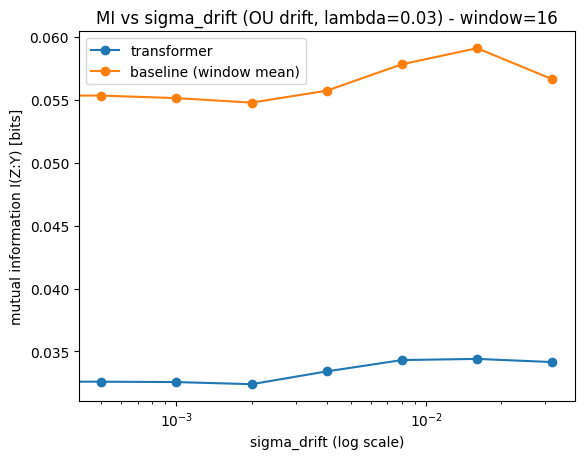

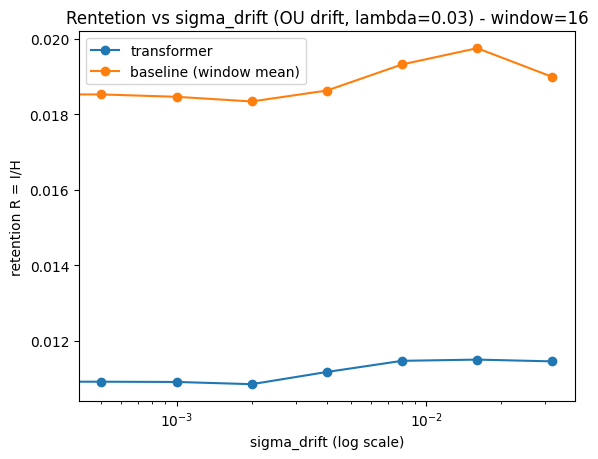

In [13]:
import matplotlib.pyplot as plt

s = [r["sigma_drift"] for r in results_ou]
mi_tf = [r["MI_transformer"] for r in results_ou]
mi_b = [r["MI_baseline_window"] for r in results_ou]
r_tf = [r["R_transformer"] for r in results_ou]
r_b = [r["R_baseline_window"] for r in results_ou]

plt.figure()
plt.plot(s, mi_tf, marker="o")
plt.plot(s, mi_b, marker="o")
plt.xscale("log")
plt.xlabel("sigma_drift (log scale)")
plt.ylabel("mutual information I(Z:Y) [bits]")
plt.title(f"MI vs sigma_drift (OU drift, lambda={lambda_ou}) - window=16")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

plt.figure()
plt.plot(s, r_tf, marker="o")
plt.plot(s, r_b, marker="o")
plt.xscale("log")
plt.xlabel("sigma_drift (log scale)")
plt.ylabel("retention R = I/H")
plt.title(f"Rentetion vs sigma_drift (OU drift, lambda={lambda_ou}) - window=16")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

In [14]:
import json
from datetime import datetime

# ---- CONFIG--------
config = {
    # data/generator
    "scenario": "ou_process_ok_sweep",
    "T": T,
    "D": 256,
    "K": K,
    "subset_size": 25,
    "overlap_target": 5,
    "seed_world": seed_world,
    "seed_world": seed_nodes,

    # evaluation protocol
    "window": window,
    "mask_ratio": mask_ratio,
    "mask_seed": 2,
    "train_val_split": 0.8,
    "bins": bins.tolist(),

    # sweep
    "sigmas": [r["sigma_drift"] for r in results_ou],

    # model_file
    "model_weights": "run_ou_lambda0p03_fixed_window16_model.pt",

    # model hyperparameters (must match how we trained)
    "model_hparams": {
        "d_model": 128,
        "nhead": 4,
        "num_layers": 3,
        "dim_ff": 256,
        "dropout": 0.1
    }
}

run = {
    "config": config,
    "results": results_ou
}

# ---- save ----
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
fname = f"drift_sweep_run_{stamp}.json"

with open(fname, "w") as f:
    json.dump(run, f, indent=2)

print("saved:", fname)

saved: drift_sweep_run_20260202_134254.json


In [15]:
import csv

csv_name = fname.replace(".json", ".csv")
keys = results_ou[0].keys()

with open(csv_name, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=keys)
    w.writeheader()
    w.writerows(results_ou)

print("saved:", csv_name)


saved: drift_sweep_run_20260202_134254.csv


Reducing the temporal context to 32 steps eliminates the transformer’s advantage under OU drift. In this regime, prediction is dominated by local stationarity, and a simple window-mean baseline outperforms the learned representation across all drift strengths. This indicates that failure arises not from nonstationarity itself, but from insufficient context relative to the process correlation time.

plots doesnt show any phase transition.

1) What counts as a phase transition in our setup?

In our framework (information-theoretic evaluation of sequence models), a phase transition would look like at least one of the following:

* Non-analytic behavior:
– a sharp kink, discontinuity, or sudden slope change in MI or retention
* Order-parameter collapse:
– MI or R=I/H dropping abruptly toward zero at some critical σ*
* Regime crossing:
– a sudden swap in dominance (transformer ≫ baseline → transformer ≪ baseline) over a very narrow σ range
* Scaling instability:
– strong sensitivity to σ in a narrow band, not smooth curvature

2) Why the observed peak is not a phase transition
(A) The peak is smooth and broad
* Both curves rise gradually and fall gradually
* No sharp knee
* No discontinuity in slope

This is classic finite-size smooth response, not criticality.

We observe a broad maximum in mutual information at intermediate drift strengths, reflecting a crossover where the OU correlation time matches the model’s temporal context. This behavior does not constitute a phase transition, as performance varies smoothly with σ and no abrupt change or collapse is observed.

It indicates timescale matching (crossover)